# Week 7

In [38]:
import jax
jax.config.update("jax_enable_x64", True) 

In [39]:
from src.api.v5 import (
    GaussEmission, 
    StaticTransition, 
    DynamicTransition,
    Params, 
    LBFGSSolver, 
    AutoregressiveGaussEmission, 
    MultivariateAutoregressiveGaussEmission, 
    MultivariateGaussEmission, 
    BackwardSampler, 
    ForwardAlgorithm
    )


from drivers.utils import (
    load_y_df, 
    build_covariates, 
    harmonic_range, 
    load_base_data_path
    )
import numpy as np
import jax.numpy as jnp
from dataclasses import dataclass
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
  

In [40]:
ROOM_SLUG, TAG  = "room_019", "30min"  
STATES = 6

# --- Covariates entering the transition -------------------------------------------
USE_OFF_DAY     = True     # weekend / Danish public holiday flag


# --- Calendar cycles (0 drops the block entirely) ---------------------------------
N_DAILY_CYCLES  = [1]     # -> sin_tod_1..k  / cos_tod_1..k
N_WEEKLY_CYCLES = [1]     # -> sin_week_1..k / cos_week_1..k


In [41]:

data_dir = Path(load_base_data_path()) / ROOM_SLUG / TAG
meta     = pd.read_csv(data_dir / "metadata.csv").iloc[0]
BIN          = meta["bin"]


ys_train_df = load_y_df(ROOM_SLUG, TAG, "train")  # the driver's X_*.csv are not used: 

dates     = pd.date_range(meta["start"], periods=len(ys_train_df), freq=BIN)

X_raw, covariate_cols = build_covariates(
    dates,
    tod_harmonics=harmonic_range(N_DAILY_CYCLES),
    week_harmonics=harmonic_range(N_WEEKLY_CYCLES),
    use_off_day=USE_OFF_DAY,
    weather_cols=[],
)

ys_train_df = ys_train_df.set_index("datetime").sort_index()  # sort by datetime, just in case 
print(f"Columns in training data: {ys_train_df.columns.tolist()}")
print()

print(f"Loaded {ROOM_SLUG}/{TAG} — {ys_train_df.shape[0]} training observations") 
print(f"Covarite cols is: {covariate_cols}")
print(f"First 5 rows of training data:\n{ys_train_df.head()}")

Columns in training data: ['co2', 'humidity', 'feedback']

Loaded room_019/30min — 2759 training observations
Covarite cols is: ['off_day', 'sin_week_1', 'cos_week_1', 'sin_tod_1', 'cos_tod_1']
First 5 rows of training data:
                            co2  humidity  feedback
datetime                                           
2023-11-13 02:30:00  449.720000  3.076717         0
2023-11-13 03:00:00  474.646667  3.004959         0
2023-11-13 03:30:00  459.573333  2.933650         0
2023-11-13 04:00:00  483.333333  2.538744         0
2023-11-13 04:30:00  490.293333  2.562512         0


In [42]:
feedback_series = jnp.asarray(ys_train_df["feedback"].to_numpy()) 
ys_train_df = ys_train_df.drop(columns=["feedback"])  # drop feedback from the training data, as it is not an observation

In [43]:
@dataclass(frozen=True)
class Data:
    ys: jnp.ndarray
    datetime: pd.Series
    ys_co2: jnp.ndarray
    ys_humidity: jnp.ndarray
    xs: jnp.ndarray  # covariates for transition
    feedback: jnp.ndarray
    ys_cols: tuple[str] = ("co2", "humidity", "feedback") # type: ignore



traindata = Data(
    ys=jnp.array(ys_train_df.values),
    datetime=ys_train_df.index, #type: ignore
    ys_co2=jnp.array(ys_train_df["co2"].values),
    ys_humidity=jnp.array(ys_train_df["humidity"].values),
    xs=jnp.asarray(X_raw),
    feedback=feedback_series,
    ys_cols=tuple(ys_train_df.columns) #type: ignore
)



results_dict = {}

# Fitting 

In [44]:
def negative_likelihood(params: Params, data: tuple) -> jax.Array:
    """Compute the negative log-likelihood of the HMM given the parameters and data."""
    from src.api.v5 import ForwardAlgorithm 
    ys, xs, inital_dist = data
    utt, f_t, u_t = ForwardAlgorithm().run(params=params, ys=ys, xs=xs, initial_dist=inital_dist)  
    val = -jnp.sum(jnp.log(f_t))  # negative log-likelihood
    return val 
    


def compute_stationary_distribution(transition_matrix: jnp.ndarray) -> jnp.ndarray:
    """Compute the stationary distribution of a Markov chain given its transition matrix."""
    num_states = transition_matrix.shape[0]
    I = jnp.eye(num_states)
    E = jnp.ones((num_states, num_states))
    e = jnp.ones((num_states, 1))
    delta = e.T @ jnp.linalg.inv(I - transition_matrix + E)
    return delta / jnp.sum(delta)  # Normalize to sum to 1



import equinox as eqx
import optax.tree_utils as otu

def nll_fixed_mu0(params: Params, data: tuple) -> jax.Array:
    """NLL with mu0 forced to the value carried in data, so it can't be optimised."""
    mu0, inner = data
    return negative_likelihood(eqx.tree_at(lambda p: p.emission.mu0, params, mu0), inner)


def profile_likelihood_mu0(mu0_range: jnp.ndarray, params: Params, data: tuple, solver: LBFGSSolver) -> jnp.ndarray:
    """Profile the negative log-likelihood over a range of mu0 values (vmapped)."""
    def fit_one(mu0):
        _, state = solver._run(nll_fixed_mu0, params, (mu0, data))
        return otu.tree_get(state, "value")
    return jax.vmap(fit_one)(mu0_range)


from jax.flatten_util import ravel_pytree
from jax.scipy.linalg import cho_factor, cho_solve


def compute_hessian(fitted_params: Params, data: tuple) -> tuple:
    """Compute the Hessian of the negative log-likelihood at the fitted parameters."""
    fit = fitted_params                                   # your MLE
    arrays, static = eqx.partition(fit, eqx.is_array)       # trainable leaves vs the rest
    theta_hat, unravel = ravel_pytree(arrays)               # flat vector + inverse map
    def nll_flat(theta):
        return negative_likelihood(eqx.combine(unravel(theta), static), data)
    H = jax.hessian(nll_flat)(theta_hat) # (p, p) observed information
    return H, unravel

def scale_hessian(H: jax.Array) -> tuple: 
    d = jnp.sqrt(jnp.abs(jnp.diag(H)))
    d = jnp.where(d == 0, 1.0, d)  # Avoid division by zero
    Hs = H / jnp.outer(d, d)  
    return Hs, d 


def compute_working_standard_errors(fitted_params: Params, data: tuple) -> Params:
    """Compute standard errors from the Hessian."""
    H, unravel = compute_hessian(fitted_params=fitted_params, data=data)            # exact Hessian via autodiff
    Hs, d = scale_hessian(H)                     # unit diagonal, same information
    cov = cho_solve(cho_factor(Hs), jnp.eye(len(d))) / jnp.outer(d, d)
    se = jnp.sqrt(jnp.diag(cov))
    params_std_errors = unravel(se)
    return params_std_errors



def get_gradient(params: Params, data: tuple) -> jax.Array:
    """Compute the gradient of the negative log-likelihood at the given parameters.""" 
    fit = params                                   # your MLE
    arrays, static = eqx.partition(fit, eqx.is_array)       # trainable leaves vs the rest
    theta_hat, unravel = ravel_pytree(arrays)               # flat vector + inverse map
    def nll_flat(theta):
        return negative_likelihood(eqx.combine(unravel(theta), static), data)
    return jax.grad(nll_flat)(theta_hat) 


def hessian_labels(params: Params) -> list[str]:
    """One label per entry of the flat vector from ravel_pytree, in the same order."""
    arrays, _ = eqx.partition(params, eqx.is_array)
    leaves_with_path, _ = jax.tree_util.tree_flatten_with_path(arrays)   # same leaf order as ravel_pytree
    labels = []
    for path, leaf in leaves_with_path:
        name = jax.tree_util.keystr(path).lstrip(".")                    # e.g. "emission.log_sigma"
        if name.endswith("transition_logits"):
            # logits[i, k] is the off-diagonal entry Γ[i, j] with j = k (k < i) or k + 1 (k >= i)
            m = leaf.shape[0]
            for i, k in np.ndindex(leaf.shape):
                j = k if k < i else k + 1
                labels.append(f"{name}[{i}->{j}]")
        elif leaf.ndim == 0:
            labels.append(name)
        else:
            labels.extend(f"{name}[{','.join(map(str, idx))}]" for idx in np.ndindex(leaf.shape))
    return labels




def get_number_of_clipped_ft(params: Params, data: Data): 
    from src.api.v5.inference.forward_algorithm import ForwardAlgorithm
    _, f_t, _ = ForwardAlgorithm().run(params=params, ys=data[0], xs=data[1], initial_dist=data[2])
    return int(jnp.sum(f_t <= 1e-100))


def get_sample_params(params: Params, data: tuple):
    ys, xs, initial_dist = data 
    u_tt, f_t, u_t = ForwardAlgorithm().run(params=params, ys=ys, xs=xs, initial_dist=initial_dist) 
    N = ys.shape[0]
    Gammas = params.transition.transition_matrices(N = N, xs=xs)
    return u_tt, Gammas 





In [45]:
#Seeding data

mu_seed = jnp.quantile(traindata.ys_co2, jnp.linspace(0.05, 0.95, STATES), axis=0)  # initial guess for means
std_seed = jnp.std(traindata.ys_co2, axis=0) * jnp.ones((STATES, ))  # initial guess for stds 
emission = GaussEmission.from_params(mu=mu_seed, sigma=std_seed)  # emission distribution


transition_matrix = jnp.diag(jnp.ones(STATES)) * 0.7 + jnp.ones((STATES, STATES)) * 0.3 / STATES  # initial guess for transition matrix
transition = StaticTransition.from_params(transition_matrix=transition_matrix)  # transition distribution


#inital_dist = compute_stationary_distribution(transition_matrix)  # initial distribution: stationary distribution of the transition matrix
inital_dist = jnp.ones((1 ,STATES)) / STATES  # initial distribution: uniform distribution over states

data = (traindata.ys_co2, None, inital_dist)  # initial distribution: all in state 0

## Fitting Univariate Model

### HMM(1)

In [46]:


emission = GaussEmission.from_params(mu=mu_seed, sigma=std_seed)  # emission distribution
transition = StaticTransition.from_params(transition_matrix=transition_matrix)  # transition distribution
gauss_params = Params(emission=emission, transition=transition)  # combine into Params object



solver = LBFGSSolver(n_iter=10_000)  # number of iterations for the optimizer

results = solver.fit(params=gauss_params, loss_fn=negative_likelihood, data=data)  # solve for parameters
fitted_gauss_params = results.params  # fitted parameters

print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")
print(f"Estimated mu0: {results.params.emission.mu0}")

results_dict["HMM(1)"] = results

Final loss: 15944.422717512121
Converged: True
Number of clipped steps in f_t: 0
Estimated mu0: 432.5606786022515


In [47]:
utt, Gammas = get_sample_params(fitted_gauss_params, data)  # sample hidden states

In [48]:
num_paths = 10_000
import time
start = time.perf_counter()
paths = BackwardSampler().run(num_paths = num_paths, Gammas = Gammas, utt = utt).block_until_ready()   # sample hidden states
print(time.perf_counter() - start)
paths.shape

1.3002736250055023


(10000, 2759)

In [49]:
from functools import partial
@partial(jax.jit, static_argnames="num_states")
def state_prob_given_feedback(feedback: jax.Array, paths: jax.Array, num_states: int):
    """
    Estimate P(state = k | feedback = 1) from sampled state paths.

    :param feedback: Array of shape (T,) with 1 for feedback, 0 otherwise
    :param paths: Array of shape (num_paths, T) of sampled states in [0, num_states-1]
    :param num_states: Number of hidden states (must be static)

    :return: (per_path, pooled)
        per_path: shape (num_paths, num_states), one distribution per path
        pooled:   shape (num_states,), the average over paths
        Each row of per_path, and pooled, sums to 1.
    """
    feedback = feedback.astype(jnp.float32)

    def count_one_path(path, feedback):
        # Number of feedback events that occurred while in state k
        return jnp.bincount(path, weights=feedback, length=num_states)

    fb_counts = jax.vmap(count_one_path, in_axes=(0, None))(paths, feedback)
    # shape (num_paths, num_states)

    n_feedback = feedback.sum()  # total number of feedback events, same for every path
    per_path = fb_counts / n_feedback
    pooled = per_path.mean(axis=0)
    return per_path, pooled

In [50]:
per_path, pooled = state_prob_given_feedback(traindata.feedback, paths, num_states=STATES)

In [52]:
pooled

Array([0.        , 0.        , 0.        , 0.04866998, 0.23171997,
       0.71961004], dtype=float32)

In [51]:
pooled.sum()

Array(1., dtype=float32)

### HMM( $\beta$, 1)

In [16]:
emission = results_dict["HMM(1)"].params.emission 
transition_matrix = results_dict["HMM(1)"].params.transition.transition_matrix()
beta_init = jnp.ones((len(covariate_cols), transition_matrix.shape[0], transition_matrix.shape[1] - 1)) * 0.05  # initial guess for beta
transition = DynamicTransition.from_params(transition_matrix=transition_matrix, beta=beta_init)
params = Params(emission=emission, transition=transition) 
  # transition distribution

In [17]:
data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters
print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")

results_dict["HMM(b,1)"] = results 

Final loss: 16139.795685511728
Converged: False
Number of clipped steps in f_t: 0


In [18]:
#We see that the conditioin number is very high
H, unravel = compute_hessian(fitted_params=results.params, data=data)

Hs, d = scale_hessian(H)
ws = jnp.linalg.eigh(Hs)[0]
tols = Hs.shape[0] * eps * jnp.max(jnp.abs(ws))
print(f"Tolerance is: {tols}")
numerically_zero = jnp.abs(ws) <= tols
print(f"Number of numerical Zeros eigenvals: {jnp.sum(numerically_zero)}")
#print(ws)

Tolerance is: nan
Number of numerical Zeros eigenvals: 0


In [19]:
gradient = get_gradient(params=results.params, data=data)
print(f"Gradient norm: {jnp.linalg.norm(gradient)}")

Gradient norm: 6.584756317701669


In [20]:
g = get_gradient(params=results.params, data=data)
H, unravel = compute_hessian(fitted_params=results.params, data=data)
labels = hessian_labels(results.params)
step = jnp.linalg.solve(H, g)              # Newton step to the (local) optimum
se = jnp.sqrt(jnp.diag(jnp.linalg.inv(H)))
print("Newton decrement (expected NLL drop):", 0.5 * g @ step)
df = pd.DataFrame({"grad": g, "step": step, "step/se": step / se}, index=labels)
print(df.reindex(df["step/se"].abs().sort_values(ascending=False).index).head(15))

Newton decrement (expected NLL drop): nan
                                            grad  step  step/se
transition.transition_logits[0->1] -1.335777e-02   NaN      NaN
transition.transition_logits[0->2]  2.104565e-02   NaN      NaN
transition.transition_logits[0->3]  2.131858e-30   NaN      NaN
transition.transition_logits[1->0] -1.902972e-01   NaN      NaN
transition.transition_logits[1->2] -8.497327e-02   NaN      NaN
transition.transition_logits[1->3]  6.146129e-07   NaN      NaN
transition.transition_logits[2->0]  5.646477e-13   NaN      NaN
transition.transition_logits[2->1]  1.558538e-01   NaN      NaN
transition.transition_logits[2->3]  1.443941e-01   NaN      NaN
transition.transition_logits[3->0]  1.238197e-12   NaN      NaN
transition.transition_logits[3->1]  1.225546e-12   NaN      NaN
transition.transition_logits[3->2]  5.893940e-01   NaN      NaN
transition.beta[0,0,0]             -2.981840e-02   NaN      NaN
transition.beta[0,0,1]              5.822702e-19   NaN      Na

In [21]:
#Printing wald conf intervals for the beta parameters
errors = compute_working_standard_errors(fitted_params=results.params, data=data) 

beta_vals = [results.params.transition.beta[i, j,k] for i in range(results.params.transition.beta.shape[0]) for j in range(results.params.transition.beta.shape[1]) for k in range(results.params.transition.beta.shape[2])]

errors_beta =[errors.transition.beta[i, j, k] for i in range(results.params.transition.beta.shape[0]) for j in range(results.params.transition.beta.shape[1]) for k in range(results.params.transition.beta.shape[2] )]

names = [f"beta[{i},{j},{k}]" for i in covariate_cols for j in range(results.params.transition.beta.shape[1]) for k in range(results.params.transition.beta.shape[2] + 1) if j!=k] 

for name, val, err in zip(names, beta_vals, errors_beta):
    ci_lower = val - 1.96 * err
    ci_upper = val + 1.96 * err
    print(f"{name}: Estimate={val:.4f}, SE={err:.4f}, 95% CI=({ci_lower:.4f}, {ci_upper:.4f})")

beta[off_day,0,1]: Estimate=81.0050, SE=nan, 95% CI=(nan, nan)
beta[off_day,0,2]: Estimate=-12.7793, SE=nan, 95% CI=(nan, nan)
beta[off_day,0,3]: Estimate=0.0500, SE=nan, 95% CI=(nan, nan)
beta[off_day,1,0]: Estimate=1.5392, SE=nan, 95% CI=(nan, nan)
beta[off_day,1,2]: Estimate=-44.2870, SE=nan, 95% CI=(nan, nan)
beta[off_day,1,3]: Estimate=-5.1367, SE=nan, 95% CI=(nan, nan)
beta[off_day,2,0]: Estimate=0.0500, SE=nan, 95% CI=(nan, nan)
beta[off_day,2,1]: Estimate=7.8798, SE=nan, 95% CI=(nan, nan)
beta[off_day,2,3]: Estimate=-35.4562, SE=nan, 95% CI=(nan, nan)
beta[off_day,3,0]: Estimate=0.0500, SE=nan, 95% CI=(nan, nan)
beta[off_day,3,1]: Estimate=0.0500, SE=nan, 95% CI=(nan, nan)
beta[off_day,3,2]: Estimate=0.8558, SE=nan, 95% CI=(nan, nan)
beta[sin_week_1,0,1]: Estimate=408.4362, SE=nan, 95% CI=(nan, nan)
beta[sin_week_1,0,2]: Estimate=30.3737, SE=nan, 95% CI=(nan, nan)
beta[sin_week_1,0,3]: Estimate=0.0500, SE=nan, 95% CI=(nan, nan)
beta[sin_week_1,1,0]: Estimate=-0.2832, SE=nan, 95

In [22]:
H, unravel = compute_hessian(results.params, data)
labels = hessian_labels(results.params)
diag = np.asarray(jnp.diag(H))
print("NaN in H:", bool(jnp.any(jnp.isnan(H))))
print("min eig H:", jnp.linalg.eigvalsh(H)[:5])
print("near-zero curvature:", [l for l, h in zip(labels, diag) if h < 1e-6])

NaN in H: True
min eig H: [nan nan nan nan nan]
near-zero curvature: ['transition.transition_logits[0->3]', 'transition.transition_logits[1->3]', 'transition.transition_logits[2->0]', 'transition.transition_logits[3->0]', 'transition.transition_logits[3->1]', 'transition.beta[0,0,1]', 'transition.beta[0,0,2]', 'transition.beta[0,1,1]', 'transition.beta[0,1,2]', 'transition.beta[0,2,0]', 'transition.beta[0,2,2]', 'transition.beta[0,3,0]', 'transition.beta[0,3,1]', 'transition.beta[1,0,2]', 'transition.beta[1,1,2]', 'transition.beta[1,2,0]', 'transition.beta[1,3,0]', 'transition.beta[1,3,1]', 'transition.beta[2,0,2]', 'transition.beta[2,1,2]', 'transition.beta[2,2,0]', 'transition.beta[2,3,0]', 'transition.beta[2,3,1]', 'transition.beta[3,0,2]', 'transition.beta[3,1,2]', 'transition.beta[3,2,0]', 'transition.beta[3,3,0]', 'transition.beta[3,3,1]', 'transition.beta[4,0,2]', 'transition.beta[4,1,2]', 'transition.beta[4,2,0]', 'transition.beta[4,3,0]', 'transition.beta[4,3,1]']


In [23]:
w, V = jnp.linalg.eigh(H)
v = pd.Series(np.asarray(V[:, 0]), index=labels)          # eigenvector of the negative eigenvalue
print(v.reindex(v.abs().sort_values(ascending=False).index).head(10))

transition.transition_logits[0->1]    1.0
transition.transition_logits[0->2]    NaN
transition.transition_logits[0->3]    NaN
transition.transition_logits[1->0]    NaN
transition.transition_logits[1->2]    NaN
transition.transition_logits[1->3]    NaN
transition.transition_logits[2->0]    NaN
transition.transition_logits[2->1]    NaN
transition.transition_logits[2->3]    NaN
transition.transition_logits[3->0]    NaN
dtype: float64


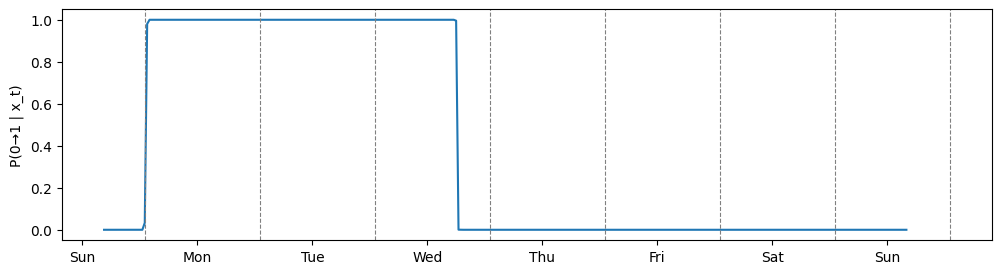

In [24]:
import matplotlib.dates as mdates
n = 48 * 7
xs = jnp.asarray(data[1])                                      # (T, D) covariates
P = jax.vmap(results.params.transition.transition_matrix)(xs)  # (T, K, K)

d = pd.to_datetime(np.asarray(dates[:n]))
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(d, P[:n, 0, 1])

ax.xaxis.set_major_locator(mdates.HourLocator(byhour=23))              # tick at each midnight
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))      # Mon, Tue, ...
for noon in pd.date_range(d[0].normalize(), d[-1], freq="D") + pd.Timedelta(hours=12):
    ax.axvline(noon, color="grey", ls="--", lw=0.8)
ax.set_ylabel("P(0→1 | x_t)")
plt.show()

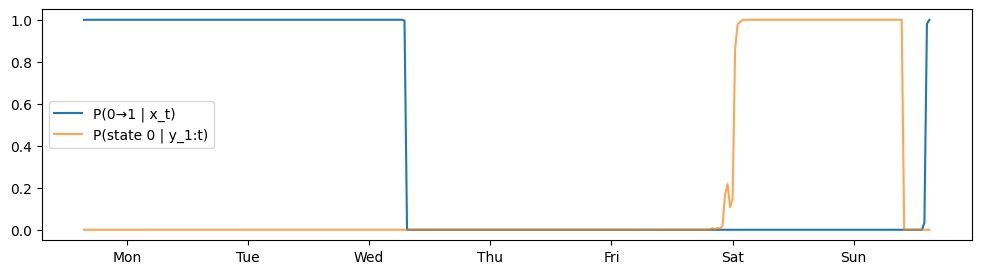

In [25]:
from src.api.v5 import ForwardAlgorithm
ys, xs, init = data
utt, f_t, u_t = ForwardAlgorithm().run(params=results.params, ys=ys, xs=xs, initial_dist=init)
fig, ax = plt.subplots(figsize=(12, 3))

M = 20
ax.plot(d, P[M: M + n, 0, 1], label="P(0→1 | x_t)")
ax.plot(d, utt[M: M + n, 0, 0], label="P(state 0 | y_1:t)", alpha=0.7)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))
ax.legend(); plt.show()

In the dynamic model the transition probability out of state 0 is a softmax of a linear predictor:

  $$
  \eta_{01}(x_t) = \alpha_{01} + \sum_c \beta_{c,01}\, x_{c,t},
  \qquad
  P(0\to 1 \mid x_t) = \frac{e^{\eta_{01}(x_t)}}{1 + \sum_{j\neq 0} e^{\eta_{0j}(x_t)}} .
  $$

  **1. The data favour a switch.** Transitions from state 0 to state 1 only happen at certain times (e.g. weekday mornings). Ideally $P(0\to1)$ would be close to 1 at those times and close to 0
  at all others.

  **2. Smooth covariates can only make a switch by blowing up.** The covariates (`off_day`, weekly and daily harmonics) vary smoothly and are bounded in $[-1, 1]$. The only way a softmax of them
  can jump from 0 to 1 is if the coefficients become very large. Then $\eta_{01}$ swings by hundreds of units and the softmax saturates. That's why we see $\hat\beta \approx 130$.

  **3. There is no finite optimum.** Every increase in $|\beta|$ makes the switch sharper. That pushes $P(0\to1)$ closer to 1 when the transition happens and closer to 0 when it doesn't. The 
  likelihood therefore keeps improving, by smaller and smaller amounts, as $|\beta| \to \infty$. This is called **separation**, the same issue as in logistic regression. The optimiser stops only 
  because the per-iteration gain falls below `tol`, which is why the gradient is not zero.

  **4. The Hessian is no longer positive definite.** When the softmax saturates, the NLL is flat in some directions (the curvature $\approx p(1-p) \approx 0$) and curves slightly downwards in one
  direction. That direction is the eigenvector of the negative eigenvalue ($\lambda_{\min} \approx -4\cdot10^{-4}$). It loads on $\alpha_{01}$ and $\beta_{\cdot,01}$, i.e. exactly the 0→1
  parameters. So the fitted point is not a local minimum.

  **5. Consequences:**
  - The Cholesky factorisation needs a positive definite matrix. It fails here and returns NaN for every standard error.
  - Even if we invert $H$ some other way, Wald standard errors and confidence intervals are not valid. They assume the likelihood is quadratic around a finite optimum, and here it isn't.
  - The parameters for transitions that essentially never happen (out of states 2 and 3) have curvature $\approx 0$. The data contain no information about them.

  **6. Fixes:**
  - Replace the harmonics for 0→1 with a covariate that matches the switch (e.g. an indicator for workday mornings).
  - Or add a ridge penalty $\tfrac{\lambda}{2}\lVert\beta\rVert^2$ so the optimum is finite.


  What happens is that the fitted model learns that in the weekends, the prob of going out of state 0 becomes very low. And due to harmocis swings, it very heavily set the weeknd covariate to a very high value, which is why we see the large $\beta$ values. This mean that the prob of going out of state 0 in the night in workdays is 1, but the chain is never in state 0 during the night in workdays, so this part of the coefficient is never used. 

In [26]:
working_hours = jnp.array([1 if 8 <= dt.hour < 17 and (dt.weekday() <= 5)  else 0 for dt in traindata.datetime ])  # 1 for working hours (8 AM to 5 PM, Mon-Fri), else 
X_raw = jnp.column_stack((X_raw, working_hours))  # Add working hours as a new covariate 

emission = results_dict["HMM(1)"].params.emission 

transition_matrix = results_dict["HMM(1)"].params.transition.transition_matrix()
beta_init = jnp.ones((len(covariate_cols) + 1, transition_matrix.shape[0], transition_matrix.shape[1] - 1)) * 0.05  # initial guess for beta
transition = DynamicTransition.from_params(transition_matrix=transition_matrix, beta=beta_init)
params = Params(emission=emission, transition=transition) 

data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0 
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters


print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")

Final loss: 16125.093855716726
Converged: False
Number of clipped steps in f_t: 0


### HMM( $\beta$, 1), Shared Cols

In [27]:
from src.api.v5.hmm.transitions.dynamic_transition import DynamicTransitionColsShared 

beta_init = jnp.ones((len(covariate_cols) + 1, transition_matrix.shape[1] - 1)) * 0.05  # initial guess for beta
transition = DynamicTransitionColsShared.from_params(transition_matrix=transition_matrix, beta=beta_init)
params = Params(emission=emission, transition=transition) 

results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters


print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")

results_dict["HMM(b,1) shared cols"] = results

Final loss: 16201.24210612092
Converged: True
Number of clipped steps in f_t: 0


In [28]:
H, unravel = compute_hessian(fitted_params=results.params, data=data) 

print(f"Condition number of HMM(b,1) shared cols is: {jnp.linalg.cond(H)}") 
tol = H.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(H))) 
print(f"Tolerance is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(H) < -tol)
print(f"Number of negative eigenvalues: {negative_eigenvalues}")
print(f"Number of numerical zeros: {jnp.sum(jnp.abs(jnp.linalg.eigvalsh(H)) <= tol)}")
gradient = get_gradient(params=results.params, data=data)
print(f"Gradient norm: {jnp.linalg.norm(gradient)}")

Condition number of HMM(b,1) shared cols is: 2.012309077548992e+17
Tolerance is: 6.437357625070313e-11
Number of negative eigenvalues: 0
Number of numerical zeros: 5
Gradient norm: 8.264236322127336e-07


In [29]:
Hs, d = scale_hessian(H)
eigenvals = jnp.linalg.eigvalsh(Hs)
tols = Hs.shape[0] * eps * jnp.max(jnp.abs(eigenvals))
print(f"Tolerance is: {tols}")
numerically_zero = jnp.abs(eigenvals) <= tols
print(f"Number of numerical Zeros eigenvals: {jnp.sum(numerically_zero)}")
negative_eigenvals = eigenvals < -tols
print(f"Number of negative eigenvals: {jnp.sum(negative_eigenvals)}")


Tolerance is: 2.852328927178089e-14
Number of numerical Zeros eigenvals: 0
Number of negative eigenvals: 0


In [30]:
def lrt(ll_null, ll_alt, df):
    """Perform a likelihood ratio test given the log-likelihoods of the null and alternative models and the degrees of freedom."""
    from scipy.stats import chi2
    test_statistic = 2 * (ll_alt - ll_null)
    p_value = chi2.sf(test_statistic, df)
    return test_statistic, p_value

In [31]:
dfs = len(results_dict["HMM(b,1) shared cols"].params.transition.beta.flatten())  # number of parameters in the alternative model


test_statistic, p_value = lrt(-results_dict["HMM(1)"].loss, -results_dict["HMM(b,1) shared cols"].loss, df=dfs) 

print("Likehood between HMM(1) and HMM(b,1) shared cols")
print(f"Likelihood Ratio Test Statistic: {test_statistic:.4f}")
print(f"P-value: {p_value:.4e}")

print(f"Current number of models: {results_dict.keys()}")

Likehood between HMM(1) and HMM(b,1) shared cols
Likelihood Ratio Test Statistic: 90.6010
P-value: 1.1261e-11
Current number of models: dict_keys(['HMM(1)', 'HMM(b,1)', 'HMM(b,1) shared cols'])


In [32]:
params = results_dict["HMM(b,1) shared cols"].params 
logits = params.transition.transition_logits
beta_vals = params.transition.beta 

print(f"Estimated transition logits for HMM(b,1) shared cols:\n{logits}")
print(f"Estimated beta values for HMM(b,1) shared cols:\n{beta_vals}") 


Estimated transition logits for HMM(b,1) shared cols:
[[ -6.01665616  -7.83788315 -74.38292254]
 [ -5.94024952  -7.02727731 -35.99788028]
 [-34.5779588   -6.51254508  -6.74977281]
 [-33.76846419 -33.77164659  -6.25397228]]
Estimated beta values for HMM(b,1) shared cols:
[[-0.69301464 -1.40757214 -1.3691193 ]
 [-0.63439504 -0.89825932 -0.32853057]
 [ 1.89486605  1.07101867  0.39834289]
 [-0.06755494  1.12993703  2.34406867]
 [-0.19220466  1.99117854  3.6316558 ]
 [ 1.03825235  4.90501273  5.81644016]]


Fitting with a ridge penality

In [33]:
def nll_ridge(Params: Params, data: tuple): 
    """Compute the negative log-likelihood of the HMM given the parameters and data, with ridge penalty on beta."""
    ys, xs, inital_dist, lam = data
    nll = negative_likelihood(Params, (ys, xs, inital_dist))
    beta_hat = jnp.ravel(Params.transition.beta)  # Flatten beta to a 1D array
    ridge_penalty = lam * jnp.sum(beta_hat ** 2)  # Ridge penalty term
    return nll + ridge_penalty  # Total loss = NLL + Ridge


In [34]:
emission = results_dict["HMM(1)"].params.emission 

transition_matrix = results_dict["HMM(1)"].params.transition.transition_matrix()
beta_init = jnp.ones((len(covariate_cols) + 1, transition_matrix.shape[0], transition_matrix.shape[1] - 1)) * 0.05  # initial guess for beta
transition = DynamicTransition.from_params(transition_matrix=transition_matrix, beta=beta_init)
params = Params(emission=emission, transition=transition) 

data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist, 0.05)  # initial distribution: all in state 0 
results = solver.fit(params=params, loss_fn=nll_ridge, data=data)  # solve for parameters


print(f"Final loss: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")

Final loss: 16147.879093502435
Converged: True
Number of clipped steps in f_t: 0


### AR(1)-HMM(1)

In [68]:
phi = jnp.ones(STATES) * 0.05
mu = fitted_gauss_params.emission.mu(t=0, ys=0) 
std = fitted_gauss_params.emission.sigma(t=0, ys=0)

In [69]:

emission = AutoregressiveGaussEmission.from_params(mu=mu, sigma=std, phi=phi)  # emission distribution

transition = fitted_gauss_params.transition  # transition distribution 

ar1_params = Params(emission=emission, transition=transition)  # combine into Params object 

data = (traindata.ys_co2,  None, inital_dist)  # initial distribution: all in state 0

results_ar1 = solver.fit(params=ar1_params, loss_fn=negative_likelihood, data=data)  # solve for parameters

fitted_ar1_params = results_ar1.params  # fitted parameters
print(f"Final loss for AR(1)-HMM(1): {results_ar1.loss}")
print(f"Converged: {results_ar1.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results_ar1.params, data)}")


results_dict["AR(1)-HMM(1)"] = results_ar1



Final loss for AR(1)-HMM(1): 13478.37995106733
Converged: True
Number of clipped steps in f_t: 0


In [70]:
H, unravel = compute_hessian(fitted_ar1_params, data)
Hs, d = scale_hessian(H)

tols = Hs.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(Hs)))
print(f"Tolerance is: {tols}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(Hs) < -tol)
print(f"Number of negative eigenvalues: {negative_eigenvalues}") 
print(f"Number of numerical zeros: {jnp.sum(jnp.abs(jnp.linalg.eigvalsh(Hs)) <= tols)}")

Tolerance is: 1.0767184628129123e-14
Number of negative eigenvalues: 0
Number of numerical zeros: 0


In [71]:
phi_vals = fitted_ar1_params.emission.phi() 


print(f"Estimated phi values for AR(1)-HMM(1): {phi_vals}")
print(f"Estimated mu values for AR(1)-HMM(1): {fitted_ar1_params.emission.mu_vals(t=0, ys=0)}")
print(f"Estimated sigma values for AR(1)-HMM(1): {fitted_ar1_params.emission.sigma(t=0, ys=0)}")
print(f"Estimated transition matrix for AR(1)-HMM(1): {fitted_ar1_params.transition.transition_matrix()}")

Estimated phi values for AR(1)-HMM(1): [[0.44775281 0.37950854 0.95206846 0.85901048]]
Estimated mu values for AR(1)-HMM(1): [ 420.58808501  510.49812512  521.17727476 2255.83406092]
Estimated sigma values for AR(1)-HMM(1): [ 19.73574337  20.12519611  25.16503662 208.11216442]
Estimated transition matrix for AR(1)-HMM(1): [[9.93727341e-01 6.27265940e-03 1.79522543e-13 4.93371927e-33]
 [1.55288634e-03 9.91212642e-01 5.28775210e-03 1.94671937e-03]
 [9.45345027e-16 2.53595140e-03 9.83121023e-01 1.43430254e-02]
 [1.99162106e-15 1.98530064e-15 7.81422483e-02 9.21857752e-01]]


In [72]:
mu_0=fitted_ar1_params.emission.mu0
params_std_errors = compute_working_standard_errors(fitted_params=fitted_ar1_params, data=data)
std = params_std_errors.emission.mu0

lower_mu = mu_0 - 3*std 
upper_mu = mu_0 + 3*std 

mu0_range = jnp.linspace(mu_0 - 3*std, mu_0 + 3*std, 60)  # range of mu0 values to profile

nll = profile_likelihood_mu0(mu0_range, fitted_ar1_params, data, LBFGSSolver(n_iter=1000))

In [73]:
print(f"Estimated mu0 for AR(1)-HMM(1): {mu_0:.4f}, SE: {std:.4f}, 95% CI: ({lower_mu:.4f}, {upper_mu:.4f})")

Estimated mu0 for AR(1)-HMM(1): 420.5881, SE: 2.8506, 95% CI: (412.0363, 429.1399)


In [74]:
params_std_errors.emission.mu0

Array(2.85060516, dtype=float64)

Text(0, 0.5, 'Likelihood')

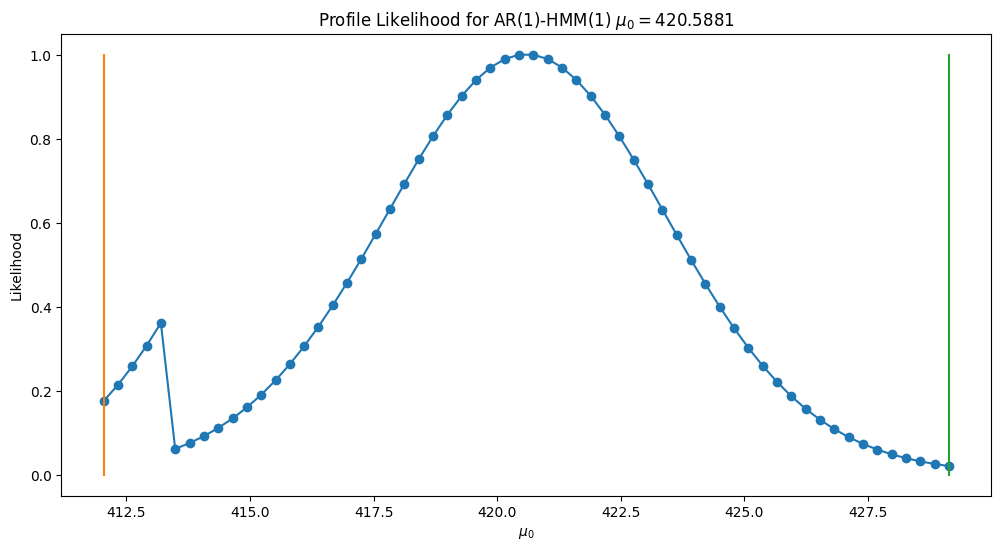

In [75]:
#Plot profile likelihood
ll = -nll  # Convert negative log-likelihood to log-likelihood for plotting
profile_likelihoods = jnp.exp(ll - jnp.max(ll))  # Convert negative log-likelihood to likelihood for plotting


plt.figure(figsize=(12, 6))
plt.plot(mu0_range, profile_likelihoods, marker='o')
plt.plot([lower_mu, lower_mu], [0, 1])
plt.plot([upper_mu, upper_mu], [0, 1])
plt.title(f"Profile Likelihood for AR(1)-HMM(1) $\mu_0=${mu_0:.4f}")
plt.xlabel("$\mu_0$")
plt.ylabel("Likelihood")

In [76]:
# Fitting different inital distributions
starts = 2

init_list = [inital_dist, jnp.array([[1.0, 0.0, 0.0, 0.0]]).T] 

inits = jax.random.uniform(jax.random.PRNGKey(0), (4, starts))

for i in range (0, starts): 
    s = inits[:, i]
    s = s / jnp.sum(s)
    init_list.append(s)

In [77]:
data_list = [(traindata.ys_co2, None, i.reshape(1,4)) for i in init_list]


ar1_params = Params(emission=emission, transition=transition)  # combine into Params object 


for i, data_set in enumerate(data_list): 
    results_run = solver.fit(params=ar1_params, loss_fn=negative_likelihood, data=data_set)  # solve for parameters
    print(f"Run {i}, converged={results_run.converged}, loss = {results_run.loss}, $\mu_0$={results_run.params.emission.mu0}")
    

Run 0, converged=True, loss = 13478.37995106733, $\mu_0$=420.5880850131043
Run 1, converged=True, loss = 13481.190833236053, $\mu_0$=420.65956198750604
Run 2, converged=True, loss = 13478.228055280519, $\mu_0$=420.58790579733767
Run 3, converged=True, loss = 13478.258432923574, $\mu_0$=420.5878076952237


### AR(1)-HMM($\beta$, 1), Shared columns

In [78]:
for modelname, result in results_dict.items(): 
    print(f"Model: {modelname}, Loss: {result.loss}, Converged: {result.converged}, Estimated mu0: {result.params.emission.mu0}")

Model: HMM(1), Loss: 16246.542625427663, Converged: True, Estimated mu0: 434.16371680410595
Model: HMM(b,1), Loss: 16139.795685511728, Converged: False, Estimated mu0: 434.394753593367
Model: HMM(b,1) shared cols, Loss: 16201.24210612092, Converged: True, Estimated mu0: 434.0063444363167
Model: AR(1)-HMM(1), Loss: 13478.37995106733, Converged: True, Estimated mu0: 420.5880850131043


In [79]:
emission = results_dict["AR(1)-HMM(1)"].params.emission
transition = results_dict["HMM(b,1) shared cols"].params.transition
params = Params(emission=emission, transition=transition)  # combine into Params object

data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0

solver = LBFGSSolver(n_iter=100_000)  # number of iterations for the optimizer

results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters

print(f"Final loss for AR(1)-HMM(b,1) shared cols: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")


results_dict["AR(1)-HMM(b,1) shared cols"] = results

Final loss for AR(1)-HMM(b,1) shared cols: 13440.69740478
Converged: True
Number of clipped steps in f_t: 0


In [82]:
H, unravel = compute_hessian(fitted_params=results.params, data=data)
Hs, d = scale_hessian(H)
tol = Hs.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(Hs)))
print(f"Tolerance is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(Hs) < -tol)
print(f"Number of negative eigenvalues: {negative_eigenvalues}")    
zero_eigenvalues = jnp.sum(jnp.abs(jnp.linalg.eigvalsh(Hs)) <= tol)
print(f"Number of numerical zeros: {zero_eigenvalues}")
eigvals = jnp.linalg.eigvalsh(H)
print(f"Eigenvalues of Hessian: {eigvals}") 

Tolerance is: 3.066960615580222e-14
Number of negative eigenvalues: 0
Number of numerical zeros: 0
Eigenvalues of Hessian: [-1.46625741e-12 -8.73342605e-13 -3.85754972e-14  1.55221255e-13
  2.96726584e-12  1.42204474e-08  2.37345297e-02  6.26283878e-02
  1.53012309e-01  1.75832343e-01  2.61901702e-01  3.41949076e-01
  4.02922764e-01  4.92031448e-01  5.63270256e-01  1.03799575e+00
  1.36872345e+00  1.89761934e+00  2.70824094e+00  2.72394368e+00
  3.37615695e+00  3.84777172e+00  4.62087016e+00  4.78092023e+00
  5.31655715e+00  9.63407326e+00  1.07699041e+01  1.08156166e+01
  1.66708895e+01  2.45704325e+01  2.69510588e+01  4.52486035e+01
  5.29119168e+01  6.49056860e+01  1.44326861e+02  3.69656346e+02
  4.52279407e+02  5.72145904e+02  1.18451204e+03  1.22629458e+03
  2.87160971e+03  5.16996001e+03]


In [83]:
phi_vals = results.params.emission.phi()
print(f"Estimated phi values for AR(1)-HMM(b,1) shared cols: {phi_vals}")

Estimated phi values for AR(1)-HMM(b,1) shared cols: [[0.60557676 0.3579428  0.95209304 0.85434289]]


### AR(2 to 8)-HMM(1)

In [84]:
init_phis = jnp.ones((2, STATES)) * 0.1
init_mu = fitted_gauss_params.emission.mu(t=0, ys=0)
init_std = fitted_gauss_params.emission.sigma(t=0, ys=0) 

In [86]:
def fit_ar1(emission: AutoregressiveGaussEmission): 
    """Fit an AR(1)-HMM model with the given emission distribution."""
    transition = results_dict["HMM(1)"].params.transition
    params = Params(emission=emission, transition=transition)  # combine into Params object
    data = (traindata.ys_co2, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0
    solver = LBFGSSolver(n_iter=100_000)  # number of iterations for the optimizer
    results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters
    minimum = is_minimum(params=results.params, data=data)  # check if the fitted parameters correspond to a local minimum
    return results, minimum

def is_minimum(params: Params, data: tuple) -> bool:
    """Check if the fitted parameters correspond to a local minimum by examining the Hessian."""
    H, _ = compute_hessian(fitted_params=params, data=data)
    eigvals = jnp.linalg.eigvalsh(H)
    tol = H.shape[0] * jnp.finfo(H.dtype).eps * jnp.max(jnp.abs(eigvals))
    num_negative = jnp.sum(eigvals < -tol)
    return bool(num_negative == 0)  # True if no negative eigenvalues, indicating a local

def init_phi_values(num_phis: int, num_states: int) -> jnp.ndarray:
    """Initialize phi values for the AR(1) emission distribution."""
    return jnp.ones((num_phis, num_states)) * 0.1  # Example initialization 

init_phi_list = [init_phi_values(num_phis, STATES) for num_phis in range(2, 3)]  # Initialize for 1 to 3 phis
emission_list = [AutoregressiveGaussEmission.from_params(mu=init_mu, sigma=init_std, phi=phi) for phi in init_phi_list]

In [87]:
results_list = [ ]

for emission in emission_list:
    results, min = fit_ar1(emission)
    if (min): 
        results_list.append(results)
    print(f"Fitted AR(1)-HMM with {emission.phi().shape[0]} phis: Loss={results.loss}, Converged={results.converged}, is minum = {min}, Estimated mu0={results.params.emission.mu0}") 
    print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")


Fitted AR(1)-HMM with 2 phis: Loss=13315.379088741298, Converged=True, is minum = True, Estimated mu0=489.69723025679224
Number of clipped steps in f_t: 0


In [88]:
results_dict["AR(2-8)-HMM(1)"] = results_list 

## Fitting Multivariate Model

We now fit multivariate models to the CO2 and Humidity data. The emission model is a multivariate Gaussian with a diagonal covariance matrix. The transition model is a dynamic transition model with covariates.

### Multi-HMM(1)

In [116]:

STATES = 5
inital_dist = jnp.ones((1 ,STATES)) / STATES  # initial distribution: uniform distribution over states

data = (traindata.ys, jnp.asarray(X_raw), inital_dist)  # initial distribution: all in state 0 
mu_init = jnp.quantile(traindata.ys, jnp.linspace(0.05, 0.95, STATES), axis=0).T  # initial guess for means
std_init = jnp.std(traindata.ys, axis=0)[:, None] * jnp.ones((STATES, ))[None, :]  # initial guess for stds 
emission = MultivariateGaussEmission.from_params(mu=mu_init, sigma=std_init)  # emission distribution
transition_matrix = jnp.diag(jnp.ones(STATES)) * 0.7 + jnp.ones((STATES, STATES)) * 0.3 / STATES  # initial guess for transition matrix
transition = StaticTransition.from_params(transition_matrix=transition_matrix)  # transition distribution
params = Params(emission=emission, transition=transition)  # combine into Params object


In [117]:
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters

In [118]:
print(f"Final loss for Multivariate HMM(1): {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")

Final loss for Multivariate HMM(1): 18584.31057619422
Converged: True
Number of clipped steps in f_t: 0


In [119]:
#Lets check if its a minimum
H, unravel = compute_hessian(fitted_params=results.params, data=data)
tol = H.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(H)))
print(f"Tolerance is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(H) < -tol)
print(f"Number of negative eigenvalues: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(jnp.linalg.eigvalsh(H)) <= tol)
print(f"Number of numerical zeros: {zero_eigenvalues}")

Tolerance is: 2.768440081259364e-10
Number of negative eigenvalues: 0
Number of numerical zeros: 9


In [120]:
Hs, d = scale_hessian(H) 
tol = Hs.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(Hs)))
print(f"Tolerance for scaled Hessian is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(Hs) < -tol)
print(f"Number of negative eigenvalues for scaled Hessian: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(jnp.linalg.eigvalsh(Hs)) <= tol)
print(f"Number of numerical zeros for scaled Hessian: {zero_eigenvalues}")

Tolerance for scaled Hessian is: 2.4186407177299148e-14
Number of negative eigenvalues for scaled Hessian: 0
Number of numerical zeros for scaled Hessian: 1


In [121]:
mu = results.params.emission.mu(t=0, ys=0)
std = results.params.emission.sigma(t=0, ys=0)
transition_matrix = results.params.transition.transition_matrix()


print(f"Estimated mu values for Multivariate HMM(1):\n"f"{np.array2string(mu, precision=4, floatmode='fixed', suppress_small=True)}")

Estimated mu values for Multivariate HMM(1):
[[ 499.5463  499.5463  524.1600  832.7309 1671.8196]
 [   1.1694    2.1927    3.0314    3.0314    3.5056]]


In [94]:
results_dict["Multi-HMM(1)"] = results

In [95]:
# We have found a minimum 
mu_0 = results.params.emission.mu0[0]
params_std_errors = compute_working_standard_errors(fitted_params=results.params, data=data)
std = params_std_errors.emission.mu0[0]
print(f"Estimated mu0: {mu_0}, SE: {std} of Co2 in Multivariate HMM(1)")

Estimated mu0: 502.8037563984909, SE: nan of Co2 in Multivariate HMM(1)


### Multi-HMM($\beta$, 1), Shared Cols

In [57]:
emission = results_dict["Multi-HMM(1)"].params.emission 
transition = results_dict["HMM(b,1) shared cols"].params.transition
params = Params(emission=emission, transition=transition)  # combine into Params object
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  # solve for parameters

print(f"Final loss for Multivariate HMM(b,1) shared cols: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")

Final loss for Multivariate HMM(b,1) shared cols: 19302.822991025114
Converged: True
Number of clipped steps in f_t: 0


In [58]:
#Lets check its a minimum
H, unravel = compute_hessian(fitted_params=results.params, data=data)
tol = H.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(H)))
print(f"Tolerance for Hessian is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(H) < -tol)
print(f"Number of negative eigenvalues for scaled Hessian: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(jnp.linalg.eigvalsh(H)) <= tol)
print(f"Number of numerical zeros for Hessian: {zero_eigenvalues}")

Tolerance for Hessian is: 2.983322599881375e-10
Number of negative eigenvalues for scaled Hessian: 0
Number of numerical zeros for Hessian: 6


In [59]:
print("Is there any logits going to inf?")
print(results.params.transition.beta )
print(results.params.transition.transition_logits)

Is there any logits going to inf?
[[  2.38867862  -0.82154163  -0.39532194]
 [  0.74174481  -1.53392656  -0.22479865]
 [ -1.17875447  -0.02935127   0.58124496]
 [  0.79102912   0.63476336   1.29852655]
 [  0.08488166   0.42209917   6.71830307]
 [  0.72862409 -25.92463075  13.50171518]]
[[ -5.83960075 -78.59271388 -74.38292254]
 [ -6.56212398  -4.76123275 -13.22181148]
 [-34.57371034  -4.53016001 -12.05219553]
 [ -8.18885695 -33.01429349 -12.67200001]]


In [60]:
eigenvals = jnp.linalg.eigvalsh(H)
mask = jnp.abs(eigenvals) <= tol 
print(f"Zero eigenvalues: {eigenvals[mask]}")

Zero eigenvalues: [-2.74420215e-10 -2.57921599e-13  1.38085266e-12  5.51652061e-12
  9.39548428e-12  1.08761131e-11]


In [61]:
jnp.diagonal(H)

Array([ 5.75607880e+00,  2.77516481e-32,  5.83369231e-27,  4.92198718e+00,
        4.88360283e+00,  3.60590114e+00,  2.33388070e-12,  7.64297269e+00,
        5.92846224e+00,  9.97985589e-01, -2.73874293e-10,  8.25205101e+00,
        7.28290200e+00,  5.06740621e+00,  3.63688177e+00,  6.31390183e+00,
        5.48055296e+00,  9.28040825e+00,  5.25763082e+00,  6.94834130e+00,
        8.04185342e+00,  5.68744577e+00,  6.65673496e+00,  1.01665852e+01,
        5.68247581e+00,  5.34366544e+00,  6.99150490e+00,  4.50396211e+00,
        9.53250783e-12,  1.63143212e+01,  1.18450458e-11,  2.90124668e+02,
        2.08549425e+03,  1.47283046e+04,  4.61925860e+03,  2.25388659e-01,
        5.18483450e-01,  1.43028509e+04,  6.57511236e+02,  1.34574745e+03,
        1.02339560e+03,  1.93277057e+03,  7.58995209e+02,  1.35025802e+03,
        1.02624238e+03,  1.91502634e+03], dtype=float64)

In [62]:
d = 1.0 / jnp.sqrt(jnp.abs(jnp.diag(H)))
print(f"Diagonal scaling factors: {d}")
Hs = d[:, None] * H * d[None, :]       # unit-magnitude diagonal
print("--------------") 
print(Hs)

tol = Hs.shape[0] * eps * jnp.max(jnp.abs(jnp.linalg.eigvalsh(Hs)))
print(f"Tolerance for Hessian is: {tol}")
negative_eigenvalues = jnp.sum(jnp.linalg.eigvalsh(Hs) < -tol)
print(f"Number of negative eigenvalues for scaled Hessian: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(jnp.linalg.eigvalsh(Hs)) <= tol)
print(f"Number of numerical zeros for Hessian: {zero_eigenvalues}")

Diagonal scaling factors: [4.16808565e-01 6.00282399e+15 1.30926706e+13 4.50743799e-01
 4.52511720e-01 5.26614838e-01 6.54576898e+05 3.61716938e-01
 4.10704036e-01 1.00100873e+00 6.04260722e+04 3.48112043e-01
 3.70550810e-01 4.44229239e-01 5.24367068e-01 3.97970690e-01
 4.27157278e-01 3.28258862e-01 4.36118948e-01 3.79366894e-01
 3.52632165e-01 4.19315934e-01 3.87587147e-01 3.13626281e-01
 4.19499263e-01 4.32593879e-01 3.78194028e-01 4.71197129e-01
 3.23889161e+05 2.47579964e-01 2.90557190e+05 5.87094040e-02
 2.18975487e-02 8.23993187e-03 1.47134278e-02 2.10636665e+00
 1.38877711e+00 8.36158665e-03 3.89985456e-02 2.72595208e-02
 3.12592264e-02 2.27462521e-02 3.62978150e-02 2.72139522e-02
 3.12158401e-02 2.28513901e-02]
--------------
[[ 1.00000000e+00 -8.72891183e-19 -1.00216490e-15 ... -4.72033483e-03
   3.49078306e-04 -1.52266953e-03]
 [-8.72891183e-19  1.00000000e+00 -5.46176316e-33 ... -2.55648602e-19
  -6.52840032e-22 -4.58582131e-20]
 [-1.00216490e-15 -5.46176316e-33  1.00000000e

In [63]:
labels = hessian_labels(results.params)
theta, _ = ravel_pytree(eqx.partition(results.params, eqx.is_array)[0])
diag = jnp.diag(H)
for i in jnp.argsort(diag)[:5]:
    print(f"{labels[i]:40s} H_ii={diag[i]:.2e}  value={theta[i]:.3f}")

transition.transition_logits[3->1]       H_ii=-2.74e-10  value=-33.014
transition.transition_logits[0->2]       H_ii=2.78e-32  value=-78.593
transition.transition_logits[0->3]       H_ii=5.83e-27  value=-74.383
transition.transition_logits[2->0]       H_ii=2.33e-12  value=-34.574
transition.beta[5,1]                     H_ii=9.53e-12  value=-25.925


We now fit with freezing parameters for the tranisiotin and emission model based on the previoues results. 

In [64]:
freeze = [("transition_logits", (0, 1))]

results = solver.fit(params=params, loss_fn=negative_likelihood, data=data, frozen=freeze)  # solve for parameters

print(f"Final loss for Multivariate HMM(b,1) shared cols: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")

results_dict["Multi-HMM(b,1) shared cols frozen"] = results

Final loss for Multivariate HMM(b,1) shared cols: 19325.97004334311
Converged: True
Number of clipped steps in f_t: 0


In [65]:
import numpy as np
from jax.flatten_util import ravel_pytree
from src.api.v5.solvers.freezer import Freezer
def compute_trainable_hessian(params, loss_fn, data, frozen=None):
    """Hessian of loss_fn w.r.t. the trainable entries only (leaf- and element-frozen ones removed)."""
    freezer = Freezer(frozen)
    trainable, static = eqx.partition(params, freezer.filter_spec(params))   # drops whole-leaf freezes
    theta, unravel = ravel_pytree(trainable)
    def leaf_mask(path, leaf):                                                 # 0 at element freezes
        m = jnp.ones(leaf.shape)
        for idx in freezer.elements.get(freezer._leaf_name(path), []):
            m = m.at[idx].set(0.0)
        return m
    mask, _ = ravel_pytree(jax.tree_util.tree_map_with_path(leaf_mask, trainable))
    free_idx = np.flatnonzero(np.asarray(mask))
    def loss_free(theta_free):
        full = theta.at[free_idx].set(theta_free)                              # frozen entries stay at their values
        return loss_fn(eqx.combine(unravel(full), static), data)
    H = jax.hessian(loss_free)(theta[free_idx])
    return H, theta[free_idx], free_idx, trainable
def trainable_labels(trainable, free_idx):
    """One label per row/column of the trainable Hessian."""
    labels = []
    for path, leaf in jax.tree_util.tree_flatten_with_path(trainable)[0]:
        name = jax.tree_util.keystr(path).lstrip(".")
        labels += [f"{name}[{','.join(map(str, i))}]" for i in np.ndindex(leaf.shape)] or [name]
    return [labels[i] for i in free_idx]
#Usage, including standard errors:
freeze = [("transition_logits", (0, 1))]
H, theta_free, free_idx, trainable = compute_trainable_hessian(results.params, negative_likelihood, data, freeze)
labels = trainable_labels(trainable, free_idx)
d = 1.0 / jnp.sqrt(jnp.abs(jnp.diag(H)))
Hs = d[:, None] * H * d[None, :]
cov = cho_solve(cho_factor(Hs), jnp.eye(len(d))) * jnp.outer(d, d)
se = jnp.sqrt(jnp.diag(cov))
pd.DataFrame({"value": theta_free, "se": se}, index=labels)

,value,se
"transition.transition_logits[0,0]",-5.750083,NaN
"transition.transition_logits[0,2]",-74.382923,NaN
"transition.transition_logits[1,0]",-6.293358,NaN
"transition.transition_logits[1,1]",-5.665725,NaN
"transition.transition_logits[1,2]",-35.997877,NaN
"transition.transition_logits[2,0]",-34.577959,NaN
"transition.transition_logits[2,1]",-5.566604,NaN
"transition.transition_logits[2,2]",-11.424044,NaN
"transition.transition_logits[3,0]",-33.768449,NaN
"transition.transition_logits[3,1]",-33.771646,NaN


In [66]:
eigvals = jnp.linalg.eigvalsh(Hs)
tol = Hs.shape[0] * eps * jnp.max(jnp.abs(eigvals))
print(f"Tolerance for scaled Hessian is: {tol}")
negative_eigenvalues = jnp.sum(eigvals < -tol)  
print(f"Number of negative eigenvalues for scaled Hessian: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(eigvals) <= tol)
print(f"Number of numerical zeros for scaled Hessian: {zero_eigenvalues}")

Tolerance for scaled Hessian is: 3.3362129826055404e-14
Number of negative eigenvalues for scaled Hessian: 4
Number of numerical zeros for scaled Hessian: 0


### AR(1)-Multi-HMM(1)

In [67]:
results_dict.keys()

dict_keys(['HMM(1)', 'HMM(b,1)', 'HMM(b,1) shared cols', 'AR(1)-HMM(1)', 'AR(1)-HMM(b,1) shared cols', 'AR(2-8)-HMM(1)', 'Multi-HMM(1)', 'Multi-HMM(b,1) shared cols frozen'])

In [68]:
phi_init = jnp.ones((1, 2, STATES)) * 0.0
mu_vals = results_dict["Multi-HMM(1)"].params.emission.mu(t=0, ys=0)
std_vals = results_dict["Multi-HMM(1)"].params.emission.sigma(t=0, ys=0)  

emission = MultivariateAutoregressiveGaussEmission.from_params(mu=mu_vals, sigma=std_vals, phi=phi_init)  # emission distribution
transition = results_dict["HMM(1)"].params.transition
params = Params(emission=emission, transition=transition)  # combine into Params object
data = (traindata.ys, None, inital_dist)  # initial distribution: all in state 0
results = solver.fit(params=params, loss_fn=negative_likelihood, data=data)  #solve for parameters

print(f"Final loss for Multivariate AR(1)-HMM(b,1) shared cols frozen: {results.loss}")
print(f"Converged: {results.converged}")
print(f"Number of clipped steps in f_t: {get_number_of_clipped_ft(results.params, data)}")


Final loss for Multivariate AR(1)-HMM(b,1) shared cols frozen: 10265.216607925791
Converged: True
Number of clipped steps in f_t: 0


In [69]:
H, unravel = compute_hessian(fitted_params = results.params, data=data) 
Hs, d = scale_hessian(H)
eigvals = jnp.linalg.eigvalsh(H)
tol = Hs.shape[0] * eps * jnp.max(jnp.abs(eigvals))
print(f"Tolerance for scaled Hessian is: {tol}")
negative_eigenvalues = jnp.sum(eigvals < -tol)  
print(f"Number of negative eigenvalues for scaled Hessian: {negative_eigenvalues}")
zero_eigenvalues = jnp.sum(jnp.abs(eigvals) <= tol)
print(f"Number of numerical zeros for scaled Hessian: {zero_eigenvalues}")


Tolerance for scaled Hessian is: 1.831409840923148e-11
Number of negative eigenvalues for scaled Hessian: 0
Number of numerical zeros for scaled Hessian: 10


In [70]:
eigenvals

Array([-2.74420215e-10, -2.57921599e-13,  1.38085266e-12,  5.51652061e-12,
        9.39548428e-12,  1.08761131e-11,  4.58438594e-02,  1.59528147e-01,
        2.85478275e-01,  4.15691051e-01,  4.40140753e-01,  5.23903713e-01,
        9.45334962e-01,  1.16121275e+00,  1.26117566e+00,  1.59078048e+00,
        2.86759908e+00,  2.94275178e+00,  3.72759575e+00,  4.49788405e+00,
        5.19619260e+00,  5.43906248e+00,  5.88998063e+00,  6.13690425e+00,
        6.21767454e+00,  7.97710670e+00,  8.04825260e+00,  8.22767667e+00,
        9.85660116e+00,  1.16840590e+01,  1.66870739e+01,  1.70595447e+01,
        3.17651801e+01,  2.71041420e+02,  6.51001121e+02,  7.41653269e+02,
        9.74527569e+02,  1.02144813e+03,  1.31699723e+03,  1.38560470e+03,
        1.62802156e+03,  1.91773319e+03,  1.93257757e+03,  2.10422703e+03,
        2.88346336e+03,  2.92080229e+04], dtype=float64)